In [1]:

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
 
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report



In [2]:
 
# ---------------------------------------------------
# 1. LOAD DATA
# ---------------------------------------------------
df = pd.read_csv("2-emails.csv")
print(df.head())
print("Shape:", df.shape)
 

  Email No.  the  to  ect  and  for  of    a  you  hou  ...  connevey  jay  \
0   Email 1    0   0    1    0    0   0    2    0    0  ...         0    0   
1   Email 2    8  13   24    6    6   2  102    1   27  ...         0    0   
2   Email 3    0   0    1    0    0   0    8    0    0  ...         0    0   
3   Email 4    0   5   22    0    5   1   51    2   10  ...         0    0   
4   Email 5    7   6   17    1    5   2   57    0    9  ...         0    0   

   valued  lay  infrastructure  military  allowing  ff  dry  Prediction  
0       0    0               0         0         0   0    0           0  
1       0    0               0         0         0   1    0           0  
2       0    0               0         0         0   0    0           0  
3       0    0               0         0         0   0    0           0  
4       0    0               0         0         0   1    0           0  

[5 rows x 3002 columns]
Shape: (5172, 3002)


In [3]:

# ---------------------------------------------------
# 2. PREPROCESSING
# ---------------------------------------------------
# Check missing values
print("Missing values:", df.isnull().sum().sum())
df = df.dropna()
 

Missing values: 0


In [4]:
# Remove the email name column (it is text, not useful for prediction)
df = df.drop(columns=["Email No."])
 

Prediction
0    3672
1    1500
Name: count, dtype: int64


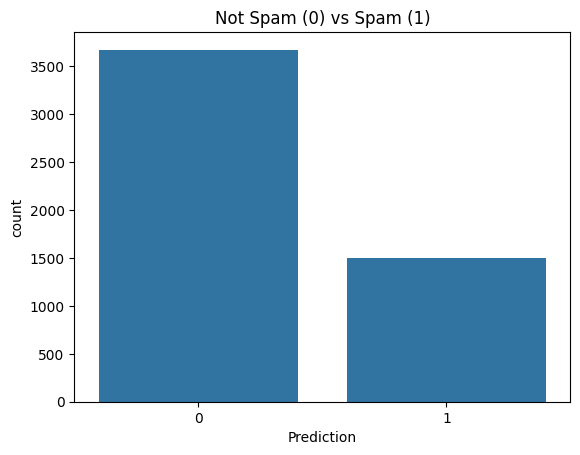

In [5]:
 
# Check how many spam (1) and not spam (0) emails
print(df["Prediction"].value_counts())
sns.countplot(x=df["Prediction"])
plt.title("Not Spam (0) vs Spam (1)")
plt.show()
 

In [6]:
# ---------------------------------------------------
# 3. SPLIT DATA
# ---------------------------------------------------
X = df.drop("Prediction", axis=1)
y = df["Prediction"]
 
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)
 


In [7]:

 
# ---------------------------------------------------
# 4. KNN
# ---------------------------------------------------
knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train, y_train)
pred_knn = knn.predict(X_test)
 
acc_knn = accuracy_score(y_test, pred_knn)
print("\nKNN Accuracy:", acc_knn)
print(confusion_matrix(y_test, pred_knn))
print(classification_report(y_test, pred_knn))
 


KNN Accuracy: 0.8628019323671497
[[645  94]
 [ 48 248]]
              precision    recall  f1-score   support

           0       0.93      0.87      0.90       739
           1       0.73      0.84      0.78       296

    accuracy                           0.86      1035
   macro avg       0.83      0.86      0.84      1035
weighted avg       0.87      0.86      0.87      1035



In [8]:
 
 
# ---------------------------------------------------
# 5. SVM
# ---------------------------------------------------
svm = SVC(kernel="linear")
svm.fit(X_train, y_train)
pred_svm = svm.predict(X_test)
 
acc_svm = accuracy_score(y_test, pred_svm)
print("\nSVM Accuracy:", acc_svm)
print(confusion_matrix(y_test, pred_svm))
print(classification_report(y_test, pred_svm))
 


SVM Accuracy: 0.9594202898550724
[[715  24]
 [ 18 278]]
              precision    recall  f1-score   support

           0       0.98      0.97      0.97       739
           1       0.92      0.94      0.93       296

    accuracy                           0.96      1035
   macro avg       0.95      0.95      0.95      1035
weighted avg       0.96      0.96      0.96      1035



In [9]:
# ---------------------------------------------------
# 6. COMPARE PERFORMANCE
# ---------------------------------------------------
result = pd.DataFrame({
    "Model": ["KNN", "SVM"],
    "Accuracy": [acc_knn, acc_svm]
})
print(result)

  Model  Accuracy
0   KNN  0.862802
1   SVM  0.959420


In [10]:

if acc_svm > acc_knn:
    print("SVM performs better.")
else:
    print("KNN performs better.")
 

SVM performs better.
